# Stage 11 — Freeze the Validated Results and Plan Scale-Up

This notebook closes the validated **2021–2023 experiment**. It has three jobs:

1. **Reproducibility freeze** — record the Python environment, Git state, and SHA-256 inventory of the data, models, figures, and notebooks used for the result.
2. **Consolidated results** — build one machine-readable headline table from the corrected walk-forward, persistence, single-split, and bloom artifacts.
3. **Scale-up preflight** — document how to extend the work without overwriting this validated run or assuming that current catalogue identifiers and date ranges remain available.

The full-record extension is a separate experiment. It must use a separate output root and a predeclared time split. Merely changing START is unsafe because several upstream filenames, download loops, sample-size checks, split dates, and fold-count gates are intentionally fixed to the validated three-year run.

## A — Reproducibility freeze

Resolve the experiment directory reliably whether Jupyter was launched from the repository root or from experiment/. Capture the environment and Git state first; the final cell writes the file inventory after all Stage 11 outputs have been refreshed.

In [1]:
import sys
import subprocess
import platform
from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import numpy as np
import pandas as pd


cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "experiment"]
EXP_DIR = next(
    (
        candidate
        for candidate in candidates
        if (candidate / "data" / "processed").is_dir()
        and (candidate / "models").is_dir()
    ),
    None,
)
if EXP_DIR is None:
    raise RuntimeError(
        "Could not locate experiment/data/processed and experiment/models. "
        "Launch this notebook from the repository root or experiment/."
    )

REPO_DIR = EXP_DIR.parent
PROC_DIR = EXP_DIR / "data" / "processed"
MODEL_DIR = EXP_DIR / "models"
FIG_DIR = EXP_DIR / "figs"


def command_output(args):
    completed = subprocess.run(
        args,
        capture_output=True,
        text=True,
        check=False,
    )
    return completed.stdout.strip() if completed.returncode == 0 else None


req_path = EXP_DIR / "requirements.txt"
freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True,
)
req_path.write_text(freeze.stdout, encoding="utf-8")
n_packages = sum(
    1
    for line in freeze.stdout.splitlines()
    if line and not line.startswith("#")
)

git_commit = command_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"]
)
git_status = command_output(
    ["git", "-C", str(REPO_DIR), "status", "--porcelain"]
)

env_info = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version.split()[0],
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "n_packages": n_packages,
    "requirements_sha256": hashlib.sha256(
        req_path.read_bytes()
    ).hexdigest(),
    "git_commit": git_commit,
    "git_worktree_dirty": bool(git_status),
}
(PROC_DIR / "environment_fingerprint.json").write_text(
    json.dumps(env_info, indent=2),
    encoding="utf-8",
)

print(f"Experiment directory : {EXP_DIR}")
print(f"Saved requirements   : {n_packages} packages")
print(f"Python               : {env_info['python_version']}")
print(f"Git commit           : {git_commit or 'unavailable'}")
print(f"Git worktree dirty   : {env_info['git_worktree_dirty']}")

Experiment directory : C:\GIT\mcast.pages.ai.v2\experiment
Saved requirements   : 162 packages
Python               : 3.14.2
Git commit           : e441c6c2eeaf629557fcdfde9a7ede34c7743cca
Git worktree dirty   : True


In [2]:
def file_digest(file_path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    if file_path.suffix == ".ipynb":
        notebook_data = json.loads(
            file_path.read_text(encoding="utf-8")
        )
        canonical = {
            "nbformat": notebook_data["nbformat"],
            "nbformat_minor": notebook_data["nbformat_minor"],
            "metadata": notebook_data.get("metadata", {}),
            "cells": [
                {
                    "cell_type": cell["cell_type"],
                    "metadata": cell.get("metadata", {}),
                    "source": cell.get("source", []),
                }
                for cell in notebook_data["cells"]
            ],
        }
        payload = json.dumps(
            canonical,
            sort_keys=True,
            ensure_ascii=False,
            separators=(",", ":"),
        ).encode("utf-8")
        digest.update(payload)
        return digest.hexdigest(), "notebook_source_without_outputs"

    with file_path.open("rb") as handle:
        while chunk := handle.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest(), "file_bytes"


def build_inventory():
    inventory_path = PROC_DIR / "file_inventory.csv"
    raw_dir = EXP_DIR / "data" / "raw"
    targets = {
        "raw inputs": [
            raw_dir / "chl_malta_2021_2023.nc",
            raw_dir / "sst_malta_2021_2023.nc",
            raw_dir / "bathy_malta.nc",
            raw_dir / "phy_sal.nc",
            raw_dir / "phy_cur.nc",
            raw_dir / "phy_ssh.nc",
            raw_dir / "phy_mld.nc",
            raw_dir / "oc_kd490.nc",
            raw_dir / "era5_wind_2021_2023.nc",
        ],
        "acquisition cache": [
            raw_dir / "era5_hourly_parts",
        ],
        "processed": [PROC_DIR],
        "models": [MODEL_DIR],
        "figures": [FIG_DIR],
        "notebooks": list(EXP_DIR.glob("*.ipynb")),
        "project": [
            EXP_DIR / "PLAN.md",
            EXP_DIR / "requirements.txt",
            EXP_DIR / "SCALE_UP_RUNBOOK.md",
        ],
    }

    rows = []
    seen = set()
    for category, entries in targets.items():
        files = []
        for entry in entries:
            if entry.is_file():
                files.append(entry)
            elif entry.is_dir():
                files.extend(
                    item for item in entry.rglob("*") if item.is_file()
                )

        for file_path in sorted(files):
            resolved = file_path.resolve()
            if resolved == inventory_path.resolve() or resolved in seen:
                continue
            seen.add(resolved)
            stat = file_path.stat()
            sha256, hash_mode = file_digest(file_path)
            rows.append({
                "category": category,
                "file": file_path.relative_to(EXP_DIR).as_posix(),
                "bytes": stat.st_size,
                "modified_utc": datetime.fromtimestamp(
                    stat.st_mtime, timezone.utc
                ).isoformat(),
                "sha256": sha256,
                "hash_mode": hash_mode,
            })

    inventory = pd.DataFrame(rows).sort_values(
        ["category", "file"]
    ).reset_index(drop=True)
    inventory.to_csv(inventory_path, index=False)
    return inventory


print(
    "Inventory function prepared. The final gate will run it after "
    "all Stage 11 artifacts have been written."
)

Inventory function prepared. The final gate will run it after all Stage 11 artifacts have been written.


## B — Consolidated final results

The primary regression comparison must be apples-to-apples: the walk-forward XGBoost model and walk-forward persistence are aggregated over the same eight test quarters and the same common mask. Corrected Notebook 8b single-split scores remain a clearly labelled diagnostic. Bloom metrics are reported separately because they use the 2023 bloom test protocol from Notebook 9.

In [3]:
required_inputs = {
    "walk-forward summary": PROC_DIR / "walk_forward_summary.csv",
    "walk-forward persistence": (
        PROC_DIR / "walk_forward_persistence.csv"
    ),
    "corrected single split": PROC_DIR / "xgb_v2_scores.csv",
    "bloom skill": PROC_DIR / "bloom_skill.csv",
}
missing_inputs = [
    label
    for label, file_path in required_inputs.items()
    if not file_path.exists()
]
if missing_inputs:
    raise FileNotFoundError(
        "Missing Stage 11 inputs: " + ", ".join(missing_inputs)
    )

wf_summary = pd.read_csv(
    required_inputs["walk-forward summary"]
)
pers_wf = pd.read_csv(
    required_inputs["walk-forward persistence"]
)
single_v2 = pd.read_csv(
    required_inputs["corrected single split"]
)
bloom = pd.read_csv(required_inputs["bloom skill"])

if "evaluation_scope" in single_v2.columns:
    single_v2 = single_v2[
        single_v2["evaluation_scope"]
        == "common_persistence_mask"
    ]

pers_summary = (
    pers_wf.groupby("horizon", as_index=False)
    .agg(
        wf_persistence_rmse_mean=("rmse", "mean"),
        wf_persistence_rmse_std=("rmse", "std"),
        wf_persistence_r2_mean=("r2", "mean"),
        wf_persistence_r2_std=("r2", "std"),
        persistence_n_folds=("fold", "nunique"),
    )
)

model_summary = wf_summary.rename(columns={
    "rmse_mean": "wf_model_rmse_mean",
    "rmse_std": "wf_model_rmse_std",
    "r2_mean": "wf_model_r2_mean",
    "r2_std": "wf_model_r2_std",
})

single_summary = single_v2[
    ["horizon", "rmse", "r2", "n"]
].rename(columns={
    "rmse": "single_split_v2_rmse",
    "r2": "single_split_v2_r2",
    "n": "single_split_v2_n",
})

bloom_headline = bloom[
    bloom["definition"] == "percentile"
][
    ["horizon", "POD", "FAR", "CSI", "F1", "N", "bloom_rate"]
].rename(columns={
    "POD": "bloom_percentile_pod",
    "FAR": "bloom_percentile_far",
    "CSI": "bloom_percentile_csi",
    "F1": "bloom_percentile_f1",
    "N": "bloom_percentile_n",
    "bloom_rate": "bloom_percentile_rate",
})

headline = (
    model_summary
    .merge(pers_summary, on="horizon", validate="one_to_one")
    .merge(single_summary, on="horizon", validate="one_to_one")
    .merge(bloom_headline, on="horizon", validate="one_to_one")
    .sort_values("horizon")
    .reset_index(drop=True)
)
headline["wf_r2_lift"] = (
    headline["wf_model_r2_mean"]
    - headline["wf_persistence_r2_mean"]
)
headline["wf_rmse_improvement_pct"] = (
    100
    * (
        headline["wf_persistence_rmse_mean"]
        - headline["wf_model_rmse_mean"]
    )
    / headline["wf_persistence_rmse_mean"]
)
headline["wf_minus_single_split_r2"] = (
    headline["wf_model_r2_mean"]
    - headline["single_split_v2_r2"]
)

headline.to_csv(
    PROC_DIR / "headline_results.csv", index=False
)

display_columns = [
    "horizon",
    "wf_model_r2_mean",
    "wf_model_r2_std",
    "wf_persistence_r2_mean",
    "wf_r2_lift",
    "wf_model_rmse_mean",
    "wf_rmse_improvement_pct",
    "single_split_v2_r2",
    "wf_minus_single_split_r2",
    "bloom_percentile_f1",
    "bloom_percentile_far",
]
print("Corrected headline results:")
print(headline[display_columns].round(4).to_string(index=False))

Corrected headline results:
 horizon  wf_model_r2_mean  wf_model_r2_std  wf_persistence_r2_mean  wf_r2_lift  wf_model_rmse_mean  wf_rmse_improvement_pct  single_split_v2_r2  wf_minus_single_split_r2  bloom_percentile_f1  bloom_percentile_far
       1            0.7745           0.0793                  0.7288      0.0457              0.0914                   9.0406              0.8787                   -0.1041               0.6083                0.4495
       2            0.7020           0.0994                  0.6344      0.0677              0.1061                  10.1310              0.8387                   -0.1367               0.5377                0.5548
       3            0.6541           0.1208                  0.5452      0.1089              0.1131                  13.0304              0.8107                   -0.1566               0.5082                0.5452
       4            0.5819           0.1869                  0.4791      0.1028              0.1209                 

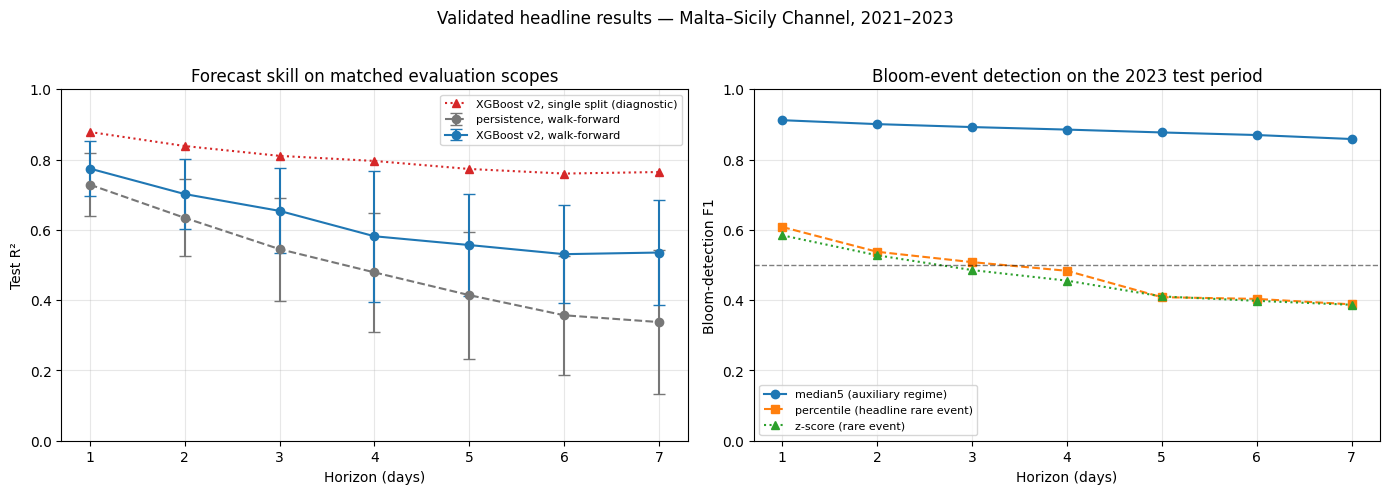

Saved figs\11_headline.png


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
horizons = headline["horizon"].to_numpy()

axes[0].errorbar(
    horizons,
    headline["wf_persistence_r2_mean"],
    yerr=headline["wf_persistence_r2_std"],
    fmt="o--",
    color="#777777",
    capsize=4,
    label="persistence, walk-forward",
)
axes[0].errorbar(
    horizons,
    headline["wf_model_r2_mean"],
    yerr=headline["wf_model_r2_std"],
    fmt="o-",
    color="#1f77b4",
    capsize=4,
    label="XGBoost v2, walk-forward",
)
axes[0].plot(
    horizons,
    headline["single_split_v2_r2"],
    "^:",
    color="#d62728",
    label="XGBoost v2, single split (diagnostic)",
)
axes[0].set(
    xlabel="Horizon (days)",
    ylabel="Test R²",
    title="Forecast skill on matched evaluation scopes",
    ylim=(0, 1),
)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

bloom_styles = [
    ("median5", "o-", "median5 (auxiliary regime)"),
    ("percentile", "s--", "percentile (headline rare event)"),
    ("zscore", "^:", "z-score (rare event)"),
]
for definition, style, label in bloom_styles:
    subset = bloom[
        bloom["definition"] == definition
    ].sort_values("horizon")
    axes[1].plot(
        subset["horizon"],
        subset["F1"],
        style,
        label=label,
    )

axes[1].axhline(
    0.5, color="black", linestyle="--", linewidth=1, alpha=0.5
)
axes[1].set(
    xlabel="Horizon (days)",
    ylabel="Bloom-detection F1",
    title="Bloom-event detection on the 2023 test period",
    ylim=(0, 1),
)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

fig.suptitle(
    "Validated headline results — Malta–Sicily Channel, 2021–2023",
    y=1.02,
)
fig.tight_layout()
figure_path = FIG_DIR / "11_headline.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {figure_path.relative_to(EXP_DIR)}")

## C — Full-record scale-up: preflight, not a blind rerun

The current 2021–2023 result is the frozen validated experiment. A full-record extension must be isolated under a new output root such as data_full/, models_full/, and figs_full/; it must never overwrite the artifacts above.

### Why changing only START is not sufficient

- Notebook 1 and Notebook 8a filenames encode 2021_2023.
- Notebook 8a’s ERA5 loop explicitly iterates over 2021–2023 and large ERA5 requests already exceeded the service cost limit; monthly requests must remain.
- Notebooks 4, 8b, 9, and 10 contain intentional checks for 360,000 rows, the 2021/2022/2023 split, and eight walk-forward folds.
- Notebook 9 fixes the climatology, cutoff-calibration, and untouched test periods. Those periods must be reassigned chronologically for a longer record.
- Dataset identifiers, versions, available dates, and depth dimensions can change. The common temporal intersection must be queried before choosing FULL_START and FULL_END.

### Required preflight

1. Query the current CMEMS/CDS catalogues and record the exact dataset IDs, versions, variables, depth selection, and available start/end dates.
2. Download a one-month pilot for every product into a new output root. Confirm grids, units, daily timestamps, surface-depth selection, and CHL-domain coverage.
3. Measure the pilot’s bytes per day and peak processing memory; extrapolate storage and runtime from those measurements instead of the old estimates.
4. Create one scale-up configuration containing the output root, common dates, monthly sample quota, random seed, and split policy. Refactor hard-coded dates, filenames, row counts, and fold counts to read that configuration.
5. Predeclare the evaluation policy. Recommended: the final complete year is untouched test data, the preceding complete year is validation/calibration data, and all earlier years are training/climatology data. Bloom cutoffs must be calibrated only on validation, never on test.
6. Run a two-year smoke test in the new output root and require every adapted leakage, coverage, feature-schema, model-schema, and evaluation gate to pass.
7. Only then submit the full acquisition. Keep ERA5 requests monthly and resumable; do not combine the full period into one request.

### Scaling notes

With stratified sampling, the nominal sample size is number_of_months × SAMPLE_PER_MONTH, but the realized count can be smaller when a month lacks enough eligible targets. Walk-forward cost also grows with both the number of quarters and the expanding training window. Benchmark the smoke test before choosing the final quota or fold schedule.

In [5]:
scale_up_readme = """# Full-Record Scale-Up Runbook

Generated by 11-Scale-Up.ipynb.

## Preserve the validated experiment

The validated 2021–2023 artifacts remain under data/, models/, and
figs/. Use separate roots such as data_full/, models_full/, and
figs_full/ for every scale-up file. Never overwrite the validated run.

## Catalogue preflight

1. Query the current CMEMS and CDS catalogues.
2. Record exact dataset IDs, versions, variables, depth selection, and
   available date ranges.
3. Choose FULL_START and FULL_END from the common temporal
   intersection; do not assume the old identifiers or endpoint still apply.
4. Download a one-month pilot for each product and verify units, grids,
   daily timestamps, surface-depth selection, and CHL-domain coverage.

## Parameterize before downloading

Create one scale-up configuration with:

- separate output roots;
- full start and end dates;
- monthly sampling quota and random seed;
- train, validation/calibration, and untouched test periods;
- walk-forward fold policy;
- pinned dataset identifiers and versions.

Refactor the year-coded filenames, the ERA5 year loop, the 360,000-row
checks, the fixed 2021/2022/2023 splits, and the eight-fold check to read
that configuration.

## Evaluation contract

Use the final complete year only for testing. Use the immediately preceding
complete year for early stopping and bloom-cutoff calibration. Use only
earlier years for model fitting and bloom climatology. Preserve the
horizon-aware boundary purge and the common persistence evaluation mask.

## Execution

1. Run a two-year smoke test in the separate output root.
2. Require the adapted acquisition, coverage, leakage, feature-schema,
   model-schema, bloom, and walk-forward gates to pass.
3. Estimate disk, memory, and runtime from the pilot and smoke test.
4. Download the full record with resumable product jobs.
5. Keep ERA5 requests monthly to avoid CDS cost-limit failures.
6. Run feature building, baselines, modeling, interpretation, bloom
   detection, and walk-forward validation in order.
7. Freeze the full-record outputs as a new result; do not replace this
   three-year manifest.

## Current validated reference

For 2021–2023, H+3 walk-forward model R² is 0.654 ± 0.121 versus
0.545 ± 0.146 for persistence on identical rows. The percentile bloom
detector has H+3 F1 of 0.508 and FAR of 0.545 on the 2023 test period.
"""

runbook_path = EXP_DIR / "SCALE_UP_RUNBOOK.md"
runbook_path.write_text(scale_up_readme, encoding="utf-8")
print(
    f"Saved {runbook_path.relative_to(EXP_DIR)} "
    f"({runbook_path.stat().st_size:,} bytes)"
)

Saved SCALE_UP_RUNBOOK.md (2,448 bytes)


---
## Validation Gate 11 — final freeze

This gate verifies the corrected artifact schemas and metrics, the walk-forward leakage audit, matched model/persistence evaluation, a non-empty UTF-8 scale-up runbook, the final figure, environment fingerprint, and a SHA-256 inventory. It raises an error on failure.

In [6]:
wf_scores = pd.read_csv(PROC_DIR / "walk_forward_scores.csv")
wf_audit = pd.read_csv(
    PROC_DIR / "walk_forward_training_audit.csv"
)
wf_manifest = json.loads(
    (PROC_DIR / "walk_forward_manifest.json").read_text(
        encoding="utf-8"
    )
)

for column in [
    "fit_end",
    "validation_start",
    "validation_end",
    "test_start",
    "test_end",
    "fit_max_label_time",
    "validation_max_label_time",
    "refit_max_label_time",
]:
    wf_audit[column] = pd.to_datetime(wf_audit[column])

h3 = headline[headline["horizon"] == 3].iloc[0]
final_manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "raw_input_period": {
        "start": "2021-01-01",
        "end": "2023-12-31",
    },
    "supervised_issue_time_period": {
        "start": "2021-01-01",
        "end": "2023-12-30",
    },
    "primary_evaluation": "eight-quarter walk-forward, common persistence mask",
    "h3": {
        "model_r2_mean": float(h3["wf_model_r2_mean"]),
        "model_r2_std": float(h3["wf_model_r2_std"]),
        "persistence_r2_mean": float(
            h3["wf_persistence_r2_mean"]
        ),
        "persistence_r2_std": float(
            h3["wf_persistence_r2_std"]
        ),
        "percentile_bloom_f1": float(
            h3["bloom_percentile_f1"]
        ),
        "percentile_bloom_far": float(
            h3["bloom_percentile_far"]
        ),
    },
    "environment_fingerprint": (
        "data/processed/environment_fingerprint.json"
    ),
    "artifact_inventory": "data/processed/file_inventory.csv",
    "scale_up_status": "preflight required; not executed",
}
final_manifest_path = PROC_DIR / "final_results_manifest.json"
final_manifest_path.write_text(
    json.dumps(final_manifest, indent=2),
    encoding="utf-8",
)

print("Hashing the frozen artifact set...")
inventory = build_inventory()
print(
    f"Inventoried {len(inventory)} files "
    f"({inventory['bytes'].sum() / 1e9:.2f} GB)."
)

results = {}

results["requirements freeze is substantial"] = (
    req_path.exists()
    and len(req_path.read_text(encoding="utf-8").splitlines()) > 50
)
results["requirements hash matches fingerprint"] = (
    hashlib.sha256(req_path.read_bytes()).hexdigest()
    == env_info["requirements_sha256"]
)
results["headline covers horizons 1 through 7"] = (
    headline["horizon"].tolist() == list(range(1, 8))
)
required_headline_columns = {
    "wf_model_r2_mean",
    "wf_model_r2_std",
    "wf_persistence_r2_mean",
    "wf_r2_lift",
    "single_split_v2_r2",
    "bloom_percentile_f1",
    "bloom_percentile_far",
}
results["headline schema is corrected"] = (
    required_headline_columns <= set(headline.columns)
)
results["headline reflects current walk-forward artifact"] = bool(
    np.allclose(
        headline["wf_model_r2_mean"],
        wf_summary.sort_values("horizon")["r2_mean"],
    )
)
results["56 walk-forward scores are present"] = (
    len(wf_scores) == 56
    and wf_scores["fold"].nunique() == 8
    and set(wf_scores["horizon"]) == set(range(1, 8))
)
results["walk-forward primary mask is correct"] = (
    wf_manifest.get("primary_evaluation_scope")
    == "common_persistence_mask"
)
results["fit labels stop before validation"] = bool(
    (
        wf_audit["fit_max_label_time"]
        <= wf_audit["fit_end"]
    ).all()
)
results["validation and refit labels stop before test"] = bool(
    (
        (
            wf_audit["validation_max_label_time"]
            <= wf_audit["validation_end"]
        )
        & (
            wf_audit["refit_max_label_time"]
            <= wf_audit["validation_end"]
        )
    ).all()
)
results["model beats matched persistence at every horizon"] = bool(
    (headline["wf_r2_lift"] > 0).all()
    and (headline["wf_rmse_improvement_pct"] > 0).all()
)
results["bloom artifact has all definitions and horizons"] = (
    len(bloom) == 21
    and set(bloom["definition"])
    == {"median5", "percentile", "zscore"}
    and set(bloom["horizon"]) == set(range(1, 8))
)

expected_notebooks = {
    "00-Environment-Setup",
    "01-Data-Acquisition",
    "02-Coverage-Atlas",
    "03-Covariates",
    "04-Build-Supervised",
    "05-Baselines",
    "06-XGBoost-Chrono",
    "07-Interpretability",
    "08a-Download-Covariates",
    "08b-Group-Importance-Ablation",
    "09-Bloom-Detection",
    "10-Walk-Forward",
    "11-Scale-Up",
}
results["all 13 notebooks are present"] = (
    expected_notebooks
    <= {notebook_path.stem for notebook_path in EXP_DIR.glob("*.ipynb")}
)

runbook_text = runbook_path.read_text(encoding="utf-8")
results["scale-up runbook is non-empty and isolated"] = (
    runbook_path.stat().st_size > 1_000
    and "separate output" in runbook_text.lower()
    and "catalogue preflight" in runbook_text.lower()
)
results["headline figure is saved"] = (
    figure_path.exists() and figure_path.stat().st_size > 10_000
)
results["final results manifest is saved"] = (
    final_manifest_path.exists()
    and final_manifest_path.stat().st_size > 500
)
results["inventory hashes are complete"] = (
    len(inventory) > 40
    and inventory["sha256"].str.fullmatch(
        r"[0-9a-f]{64}"
    ).all()
)

for name, passed in results.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")

print("\nFrozen primary results:")
print(
    f"  H+3 model R²       : "
    f"{h3['wf_model_r2_mean']:.3f} ± "
    f"{h3['wf_model_r2_std']:.3f}"
)
print(
    f"  H+3 persistence R² : "
    f"{h3['wf_persistence_r2_mean']:.3f} ± "
    f"{h3['wf_persistence_r2_std']:.3f}"
)
print(
    f"  H+3 bloom F1 / FAR : "
    f"{h3['bloom_percentile_f1']:.3f} / "
    f"{h3['bloom_percentile_far']:.3f}"
)

failed = [name for name, passed in results.items() if not passed]
if failed:
    raise RuntimeError(
        "Validation Gate 11 failed:\n- " + "\n- ".join(failed)
    )

print("\nGate 11 PASSED — validated experiment frozen.")
print(
    "The full-record extension remains a separate, "
    "catalogue-checked experiment."
)

Hashing the frozen artifact set...


Inventoried 129 files (1.43 GB).
PASS  requirements freeze is substantial
PASS  requirements hash matches fingerprint
PASS  headline covers horizons 1 through 7
PASS  headline schema is corrected
PASS  headline reflects current walk-forward artifact
PASS  56 walk-forward scores are present
PASS  walk-forward primary mask is correct
PASS  fit labels stop before validation
PASS  validation and refit labels stop before test
PASS  model beats matched persistence at every horizon
PASS  bloom artifact has all definitions and horizons
PASS  all 13 notebooks are present
PASS  scale-up runbook is non-empty and isolated
PASS  headline figure is saved
PASS  final results manifest is saved
PASS  inventory hashes are complete

Frozen primary results:
  H+3 model R²       : 0.654 ± 0.121
  H+3 persistence R² : 0.545 ± 0.146
  H+3 bloom F1 / FAR : 0.508 / 0.545

Gate 11 PASSED — validated experiment frozen.
The full-record extension remains a separate, catalogue-checked experiment.


---
## End of the validated pipeline

The thirteen notebooks now preserve one defensible 2021–2023 experiment, including corrected walk-forward uncertainty and bloom-event evaluation. SCALE_UP_RUNBOOK.md describes the separate preflight required before extending the temporal record.